In [1]:
import os
import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt




In [2]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')



Mounted at /content/drive


In [3]:
# Define paths (Update these to match your Google Drive directories)
base_path = "/content/drive/MyDrive/ProjectTask1"
train_data_path = os.path.join(base_path, "train_data")
val_data_path = os.path.join(base_path, "val_data")
train_labels_path = os.path.join(base_path, "train_labels.txt")
val_labels_path = os.path.join(base_path, "val_labels.txt")

print(f"Train Data Path: {train_data_path}")
print(f"Validation Data Path: {val_data_path}")
print(f"Train Labels Path: {train_labels_path}")
print(f"Validation Labels Path: {val_labels_path}")



Train Data Path: /content/drive/MyDrive/ProjectTask1/train_data
Validation Data Path: /content/drive/MyDrive/ProjectTask1/val_data
Train Labels Path: /content/drive/MyDrive/ProjectTask1/train_labels.txt
Validation Labels Path: /content/drive/MyDrive/ProjectTask1/val_labels.txt


In [4]:
# Load labels
def load_labels(label_file):
    with open(label_file, "r") as f:
        labels = [int(line.strip()) for line in f.readlines()]
    return labels

train_labels = load_labels(train_labels_path)
val_labels = load_labels(val_labels_path)



In [5]:
# Custom Dataset Class
class FlowerDataset(Dataset):
    def __init__(self, images_folder, labels, transform=None):
        self.images_folder = images_folder
        self.labels = labels
        self.transform = transform
        self.image_files = sorted(os.listdir(images_folder))

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img_path = os.path.join(self.images_folder, self.image_files[idx])
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        label = self.labels[idx] - 1  # Zero-based indexing

        if self.transform:
            image = self.transform(image)

        return image, label

# Image transformations
transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])



In [6]:
# Prepare datasets and dataloaders
train_dataset = FlowerDataset(train_data_path, train_labels, transform=transform)
val_dataset = FlowerDataset(val_data_path, val_labels, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)



In [7]:
# Define the model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = models.resnet18(pretrained=True)

# Modify the final layer for 60 classes
num_classes = 60
model.fc = nn.Linear(model.fc.in_features, num_classes)
model = model.to(device)

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)



/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:00<00:00, 70.4MB/s]


In [8]:
# Training and validation loop
def train_and_evaluate(model, train_loader, val_loader, criterion, optimizer, epochs=20):
    train_acc_list, val_acc_list = [], []
    train_loss_list, val_loss_list = [], []

    for epoch in range(epochs):
        model.train()
        train_loss, train_correct = 0, 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            # Forward pass
            outputs = model(images)
            loss = criterion(outputs, labels)

            # Backward pass
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            # Metrics
            train_loss += loss.item()
            train_correct += (outputs.argmax(dim=1) == labels).sum().item()

        train_loss /= len(train_loader)
        train_acc = train_correct / len(train_dataset)

        # Validation phase
        model.eval()
        val_loss, val_correct = 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item()
                val_correct += (outputs.argmax(dim=1) == labels).sum().item()

        val_loss /= len(val_loader)
        val_acc = val_correct / len(val_dataset)

        # Store metrics
        train_acc_list.append(train_acc)
        val_acc_list.append(val_acc)
        train_loss_list.append(train_loss)
        val_loss_list.append(val_loss)

        print(f"Epoch {epoch+1}/{epochs}, Train Loss: {train_loss:.4f}, "
              f"Train Acc: {train_acc:.4f}, Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

    return train_loss_list, val_loss_list, train_acc_list, val_acc_list



In [9]:
# Train the model
train_loss, val_loss, train_acc, val_acc = train_and_evaluate(
    model, train_loader, val_loader, criterion, optimizer, epochs=20
)



Epoch 1/20, Train Loss: 1.4376, Train Acc: 0.6437, Val Loss: 1.0405, Val Acc: 0.7250
Epoch 2/20, Train Loss: 0.4158, Train Acc: 0.8923, Val Loss: 0.7588, Val Acc: 0.7967
Epoch 3/20, Train Loss: 0.2763, Train Acc: 0.9207, Val Loss: 0.5482, Val Acc: 0.8567
Epoch 4/20, Train Loss: 0.1273, Train Acc: 0.9670, Val Loss: 0.4409, Val Acc: 0.8850
Epoch 5/20, Train Loss: 0.1108, Train Acc: 0.9667, Val Loss: 0.6076, Val Acc: 0.8367
Epoch 6/20, Train Loss: 0.0958, Train Acc: 0.9730, Val Loss: 0.6000, Val Acc: 0.8500
Epoch 7/20, Train Loss: 0.1028, Train Acc: 0.9707, Val Loss: 0.4927, Val Acc: 0.8667
Epoch 8/20, Train Loss: 0.0689, Train Acc: 0.9827, Val Loss: 0.3587, Val Acc: 0.9167
Epoch 9/20, Train Loss: 0.0374, Train Acc: 0.9933, Val Loss: 0.2195, Val Acc: 0.9367
Epoch 10/20, Train Loss: 0.0482, Train Acc: 0.9873, Val Loss: 0.5539, Val Acc: 0.8433
Epoch 11/20, Train Loss: 0.1635, Train Acc: 0.9540, Val Loss: 0.9356, Val Acc: 0.7783
Epoch 12/20, Train Loss: 0.0919, Train Acc: 0.9740, Val Loss: 0

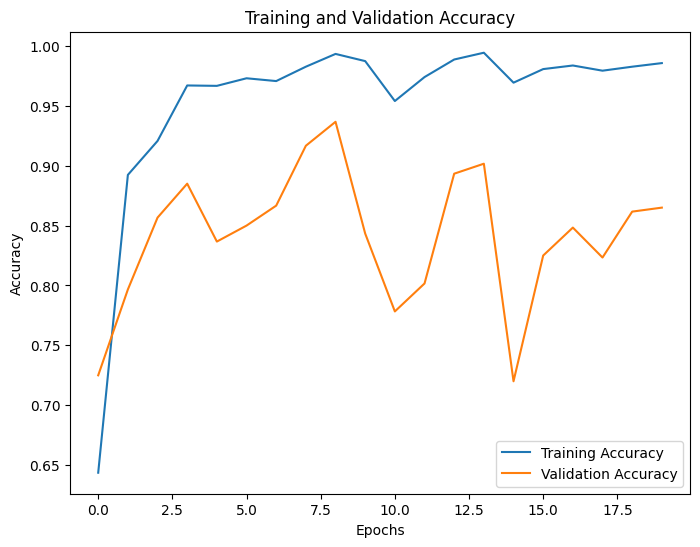

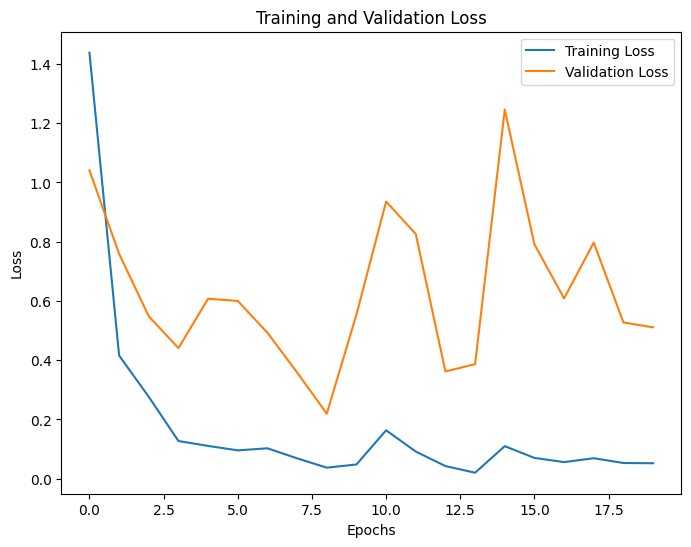

In [10]:
# Plot training and validation accuracy
plt.figure(figsize=(8, 6))
plt.plot(train_acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy')
plt.show()

# Plot training and validation loss
plt.figure(figsize=(8, 6))
plt.plot(train_loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss')
plt.show()



In [11]:
# Save the trained model
torch.save(model.state_dict(), "/content/drive/MyDrive/best_resnet_model.pth")



In [19]:
# TEST DATA CLASSIFICATION (ADDED AT THE END)

# Function to load and preprocess test images
def load_and_preprocess_images(test_data_path, transform=None):
    image_files = sorted(os.listdir(test_data_path))
    images = []
    for img_file in image_files:
        img_path = os.path.join(test_data_path, img_file)
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        if transform:
            image = transform(image)
        images.append(image)

    return images, image_files
# Load labels from a text file
def load_labels(label_file):
    with open(label_file, "r") as f:
        labels = [int(line.strip()) for line in f.readlines()]
    return labels

In [21]:
# Test data path (user will change this to their directory containing test images)
base_path = "/content/drive/MyDrive/ProjectTask1"
test_data_path = os.path.join(base_path, "val_data")  #Sir change this to the path of your test images directory
test_labels_path = os.path.join(base_path, "val_labels.txt") #Sir change this to the path of your test.txt
# Load test labels
test_labels = load_labels(test_labels_path)
# Image transformations (same as during training)
transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Load and preprocess test data
test_images, test_image_files = load_and_preprocess_images(test_data_path, transform=transform)

# Convert to tensor and create a DataLoader
test_images = torch.stack(test_images)
test_labels = torch.tensor(test_labels) - 1  # Convert to zero-based index
test_dataset = torch.utils.data.TensorDataset(test_images, test_labels)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=32, shuffle=False)

In [22]:
# Load the trained model (assuming it's already trained and saved)
model = models.resnet18(pretrained=False)
model.fc = torch.nn.Linear(model.fc.in_features, 60)  # 60 classes
model.load_state_dict(torch.load("/content/drive/MyDrive/best_resnet_model.pth"))
model.eval()

# Move model to the correct device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# Function to evaluate test data accuracy and loss
def evaluate_test_data(model, test_loader, criterion):
    model.eval()
    total_correct = 0
    total_samples = 0
    total_loss = 0.0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)

            loss = criterion(outputs, labels)
            total_loss += loss.item() * labels.size(0)

            _, predicted = torch.max(outputs, 1)
            total_correct += (predicted == labels).sum().item()
            total_samples += labels.size(0)

    accuracy = total_correct / total_samples
    avg_loss = total_loss / total_samples
    return accuracy, avg_loss

# Define the loss criterion
criterion = torch.nn.CrossEntropyLoss()

# Initialize lists to store test accuracy and loss for each epoch
test_accuracies = []
test_losses = []


<ipython-input-22-9e4e6e3fa506>:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("/content/drive/MyDrive/best_resnet_model.pth"))


Test Accuracy: 0.8650


In [ ]:
# Number of epochs for which testing data is evaluated
num_epochs = 10  # Assuming we want to simulate evaluation across 10 epochs
for epoch in range(1, num_epochs + 1):
    print(f"Evaluating Test Data - Epoch {epoch}/{num_epochs}...")
    accuracy, avg_loss = evaluate_test_data(model, test_loader, criterion)
    test_accuracies.append(accuracy)
    test_losses.append(avg_loss)
    print(f"Epoch {epoch}: Test Accuracy = {accuracy:.4f}, Test Loss = {avg_loss:.4f}")

In [ ]:
# Plot Test Accuracy vs. Epochs
plt.figure(figsize=(10, 5))
plt.plot(range(1, num_epochs + 1), test_accuracies, marker='o', label='Test Accuracy')
plt.title('Test Accuracy vs. Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

# Plot Test Loss vs. Epochs
plt.figure(figsize=(10, 5))
plt.plot(range(1, num_epochs + 1), test_losses, marker='o', color='r', label='Test Loss')
plt.title('Test Loss vs. Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

In [23]:
# Save test predictions (same as before)
all_predictions = []
model.eval()
with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        all_predictions.extend(predicted.cpu().numpy())

with open("/content/drive/MyDrive/test_predictions.txt", "w") as f:
    for img_file, pred_label in zip(test_image_files, all_predictions):
        f.write(f"{img_file}: {pred_label + 1}\n")  # Convert to 1-based indexing

print("Test predictions saved to 'test_predictions.txt'.")

Test predictions saved to 'test_predictions.txt'.


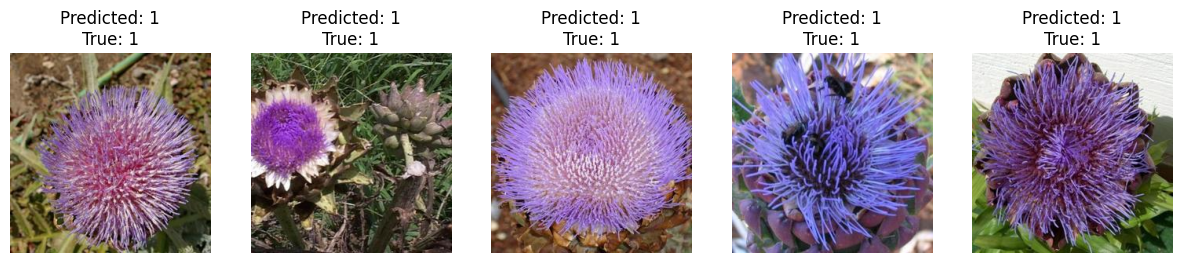

In [24]:
# Display predictions for a few test images
fig, axes = plt.subplots(1, 5, figsize=(15, 5))  # Show 5 images for simplicity
for i, ax in enumerate(axes):
    if i >= len(test_predictions): break
    img_path = os.path.join(test_data_path, test_image_files[i])
    image = cv2.imread(img_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    ax.imshow(image)
    ax.set_title(f"Predicted: {test_predictions[i] + 1}\nTrue: {test_true_labels[i] + 1}")
    ax.axis('off')
plt.show()